# 02 - Modelos de alerta temprana de insolvencia

Exploración de los modelos antes de llevarlos a MLflow. Aquí se revisan los datos que entran al modelo, se comparan
la línea base de Altman, la regresión logística, el random forest y el gradient boosting, y se miran las curvas y las
variables que más pesan. El registro oficial de las corridas lo hace `experiments/entrenar_modelos.py` en el servidor
de MLflow (experimento `alerta-insolvencia`).

**Decisiones (de la Entrega 1):** universo CIIU 41, 43 y 68 (sin obras civiles, 42); objetivo `y_h1` (apertura de un
proceso de insolvencia el año siguiente); entrenamiento 2016-2021 y prueba 2022-2024 sin mezclar años; se quitan los
años posteriores al evento (`post_evento`) para evitar fuga de información.

In [1]:
import sys
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "experiments"))
# Se reutilizan las mismas funciones del script de MLflow para que el notebook y las corridas coincidan
from entrenar_modelos import (CATEGORICAS, INDICADORES, OBJETIVO, RAZONES, cargar_datos,
                              configuraciones, metricas, preprocesador)

FIGURAS = RAIZ / "docs" / "figuras"
entrenamiento, prueba = cargar_datos(RAIZ / "data" / "processed" / "resumen_empresas.csv")
X_cols = RAZONES + INDICADORES + CATEGORICAS

## 1. Cuántas empresas y eventos entran al modelo

In [2]:
resumen = (pd.concat([entrenamiento.assign(conjunto="entrenamiento"), prueba.assign(conjunto="prueba")])
           .groupby(["conjunto", "anio"])
           .agg(empresas=("nit", "size"), eventos=(OBJETIVO, "sum")))
resumen["tasa_%"] = (100 * resumen["eventos"] / resumen["empresas"]).round(2)
resumen

empresas  eventos  tasa_%
conjunto      anio                           
entrenamiento 2016      4961       14    0.28
              2017      4627       35    0.76
              2018      5147       28    0.54
              2019      6460       49    0.76
              2020      7347       20    0.27
              2021      7268       25    0.34
prueba        2022      7571       23    0.30
              2023      7524       28    0.37
              2024      6786       15    0.22

In [3]:
print(f"Entrenamiento: {len(entrenamiento):,} empresa-año y {entrenamiento[OBJETIVO].sum()} eventos")
print(f"Prueba:        {len(prueba):,} empresa-año y {prueba[OBJETIVO].sum()} eventos")
print(f"Prevalencia en prueba: {prueba[OBJETIVO].mean():.2%}")

Entrenamiento: 35,810 empresa-año y 171 eventos
Prueba:        21,881 empresa-año y 66 eventos
Prevalencia en prueba: 0.30%


Muy pocos eventos: unas 171 quiebras para aprender y 66 para evaluar. Por eso no se mira la exactitud (decir
"nadie quiebra" acierta el 99,7 %) sino AUC, AUC-PR y la captura de eventos en el 10 % de mayor riesgo, y los
modelos usan `class_weight` para que cada quiebra pese más al entrenar.

## 2. Entrenar y comparar todos los modelos

In [4]:
y_ent, y_pru = entrenamiento[OBJETIVO].to_numpy(), prueba[OBJETIVO].to_numpy()
puntajes = {"linea_base_altman": -prueba["altman_z2"].fillna(prueba["altman_z2"].median()).to_numpy()}
modelos = {}
for nombre, modelo, escalar in configuraciones():
    pipe = Pipeline([("preprocesar", preprocesador(escalar)), ("modelo", modelo)])
    pipe.fit(entrenamiento[X_cols], y_ent)
    modelos[nombre] = pipe
    puntajes[nombre] = pipe.predict_proba(prueba[X_cols])[:, 1]

tabla = pd.DataFrame({n: metricas(y_pru, p) for n, p in puntajes.items()}).T
tabla[["auc", "auc_pr", "auc_pr_sobre_prevalencia", "captura_top10"]].round(3).sort_values("auc", ascending=False)

,auc,auc_pr,auc_pr_sobre_prevalencia,captura_top10
random_forest_hoja50,0.892,0.047,15.650,0.667
random_forest_hoja20,0.886,0.048,15.873,0.652
logistica_C0.1,0.873,0.023,7.765,0.561
gradient_boosting_lr0.05,0.873,0.036,11.810,0.545
gradient_boosting_lr0.1,0.873,0.029,9.538,0.621
logistica_C1,0.872,0.023,7.672,0.576
linea_base_altman,0.676,0.006,1.897,0.182


## 3. Curvas ROC y de precisión-exhaustividad (prueba 2022-2024)

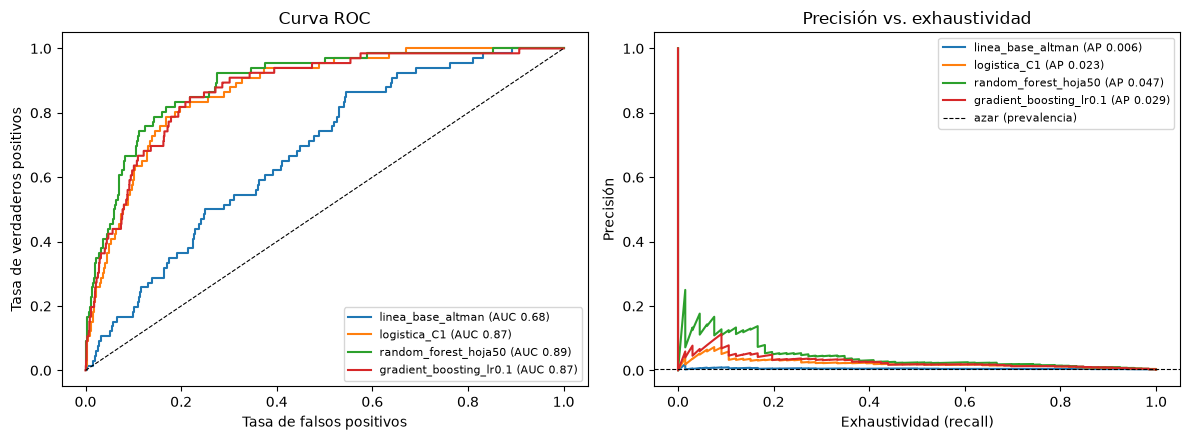

In [5]:
seleccion = ["linea_base_altman", "logistica_C1", "random_forest_hoja50", "gradient_boosting_lr0.1"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for n in seleccion:
    fpr, tpr, _ = roc_curve(y_pru, puntajes[n])
    ejes[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_pru, puntajes[n]):.2f})")
    pr, rc, _ = precision_recall_curve(y_pru, puntajes[n])
    ejes[1].plot(rc, pr, label=f"{n} (AP {average_precision_score(y_pru, puntajes[n]):.3f})")
ejes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ejes[0].set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ejes[1].axhline(y_pru.mean(), color="k", ls="--", lw=0.8, label="azar (prevalencia)")
ejes[1].set(title="Precisión vs. exhaustividad", xlabel="Exhaustividad (recall)", ylabel="Precisión")
for e in ejes:
    e.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "modelos_01_roc_pr.png", dpi=150)
plt.show()

## 4. Curva de captura: qué parte de las quiebras se encuentra revisando una fracción de empresas

Es la lectura de negocio: si el analista revisa primero las empresas con mayor riesgo, ¿qué porcentaje de las que
luego entran en insolvencia ya habrá revisado?

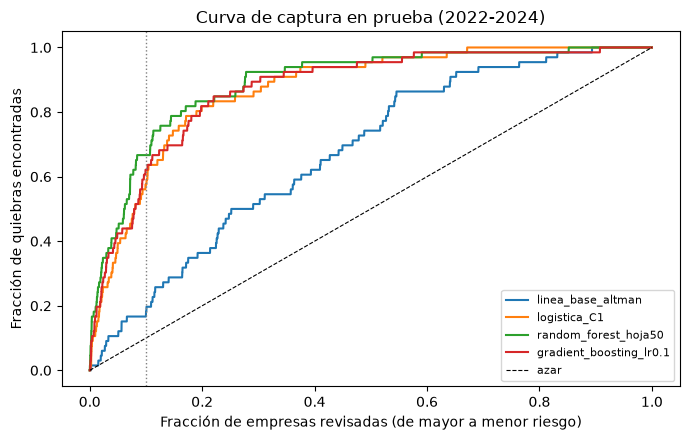

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for n in seleccion:
    orden = np.argsort(-puntajes[n])
    captura = np.cumsum(y_pru[orden]) / y_pru.sum()
    ax.plot(np.arange(1, len(orden) + 1) / len(orden), captura, label=n)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="azar")
ax.axvline(0.10, color="gray", ls=":", lw=1)
ax.set(xlabel="Fracción de empresas revisadas (de mayor a menor riesgo)", ylabel="Fracción de quiebras encontradas",
       title="Curva de captura en prueba (2022-2024)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "modelos_02_captura.png", dpi=150)
plt.show()

## 5. Qué variables pesan más

In [7]:
nombres = RAZONES + INDICADORES + ["ciiu_41", "ciiu_43", "ciiu_68"]
rf = modelos["random_forest_hoja50"].named_steps["modelo"]
log = modelos["logistica_C1"].named_steps["modelo"]
importancia = pd.DataFrame({
    "random_forest (importancia)": rf.feature_importances_,
    "logistica (coeficiente estandarizado)": log.coef_[0],
}, index=nombres).sort_values("random_forest (importancia)", ascending=False)
importancia.round(3)

,random_forest (importancia),logistica (coeficiente estandarizado)
efectivo_activos,0.126,-2.292
margen_neto,0.098,-0.379
endeudamiento,0.076,0.005
margen_operacional,0.074,0.371
ciiu_68,0.068,-1.359
ln_activos,0.064,0.413
cobertura_intereses,0.062,-0.111
roa,0.045,-0.022
apalancamiento,0.045,-0.570
pasivo_corriente_pasivo,0.044,0.107


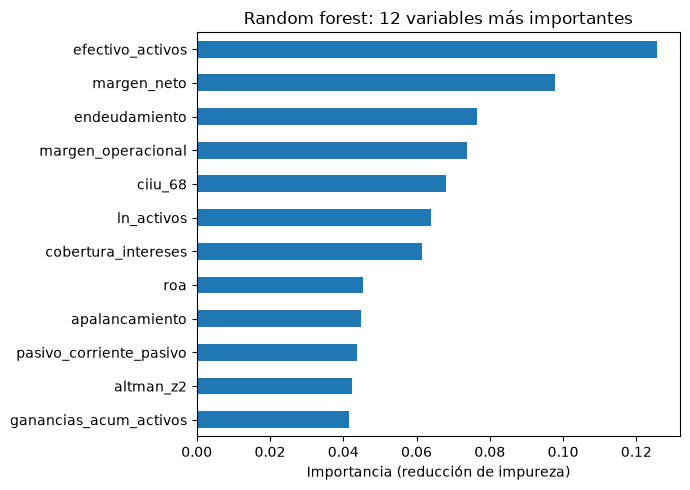

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
importancia["random_forest (importancia)"].head(12).iloc[::-1].plot.barh(ax=ax)
ax.set(title="Random forest: 12 variables más importantes", xlabel="Importancia (reducción de impureza)")
plt.tight_layout()
plt.savefig(FIGURAS / "modelos_03_importancia.png", dpi=150)
plt.show()

## 6. ¿Qué tan creíbles son las probabilidades?

In [9]:
for n in ["logistica_C1", "random_forest_hoja50", "gradient_boosting_lr0.1"]:
    print(f"{n:26} probabilidad media {puntajes[n].mean():.3f}  vs. tasa real {y_pru.mean():.3f}")

logistica_C1               probabilidad media 0.315  vs. tasa real 0.003
random_forest_hoja50       probabilidad media 0.080  vs. tasa real 0.003
gradient_boosting_lr0.1    probabilidad media 0.164  vs. tasa real 0.003


Con `class_weight` los modelos sobrestiman la probabilidad (la media queda muy por encima de la tasa real). Para
ordenar empresas por riesgo no importa, pero si el tablero va a mostrar "probabilidad de insolvencia" hay que
calibrarla (por ejemplo con `CalibratedClassifierCV`) o mostrar bandas de riesgo en vez de porcentajes.

## 7. Observaciones

- **Todos los modelos le ganan con claridad a la línea base de Altman** (AUC 0,68 y 18 % de captura en el 10 % de
  mayor riesgo): las razones financieras combinadas sí anticipan la insolvencia mejor que el Z'' solo.
- **El mejor es el random forest** (AUC cercana a 0,89 y alrededor de dos de cada tres quiebras encontradas revisando
  el 10 % de las empresas). La logística queda cerca en AUC pero captura menos en la parte alta del ranking.
- **El AUC-PR es bajo en términos absolutos** porque la prevalencia en prueba es 0,3 %; frente al azar el random
  forest es unas 16 veces mejor.
- **Las cifras son inestables:** con 66 eventos de prueba, una o dos quiebras más o menos mueven la captura varios
  puntos. Conviene reportar rangos y no sobreinterpretar diferencias pequeñas entre modelos.
- **La etiqueta solo ve la insolvencia formal ante la Supersociedades** (comentario del tutor en la Entrega 1): el
  modelo no detecta empresas que dejan de pagar sin abrir un proceso, ni las que no reportaron estados el año
  anterior.
- **Siguiente paso:** calibrar las probabilidades del modelo elegido y empaquetarlo para la API (Entrega final).